# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

Cloning into 'walmart-hurricane-project'...
remote: Enumerating objects: 67, done.
remote: Counting objects: 100% (67/67), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 67 (delta 30), reused 19 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (67/67), 1010.41 KiB | 6.65 MiB/s, done.
Resolving deltas: 100% (30/30), done.
/content/walmart-hurricane-project/walmart-hurricane-project/walmart-hurricane-project
pandas 2.2.3
transactions: 25,562 rows | stores: 14 | catalog: 45 | distribution centers: 5
transaction_id    object
store_id          object
timestamp         object
sku               object
product_name      object
category          object
quantity           int64
unit_price        object
dtype: object 

nulls per column (pandas default null detection):
transaction_id      0
store_id            0
timestamp         886
sku                 0
product_name        0
category            0
quantity            0
unit_price          0
dtype: int64 

exact dupl

,baseline_per_day,surge_per_day,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94



Baseline: 2024-09-01 to 2024-09-15 (15 days)   Surge: 2024-09-19 to 2024-09-25 (7 days, before the 2024-09-26 landfall)
All categories, units:        1,103 -> 2,712 per day = 2.46x
All categories, order lines:  576 -> 1,361 per day = 2.36x
Biggest surge: Breakfast, 73.3 -> 376.9 units/day = 5.14x (+414%)



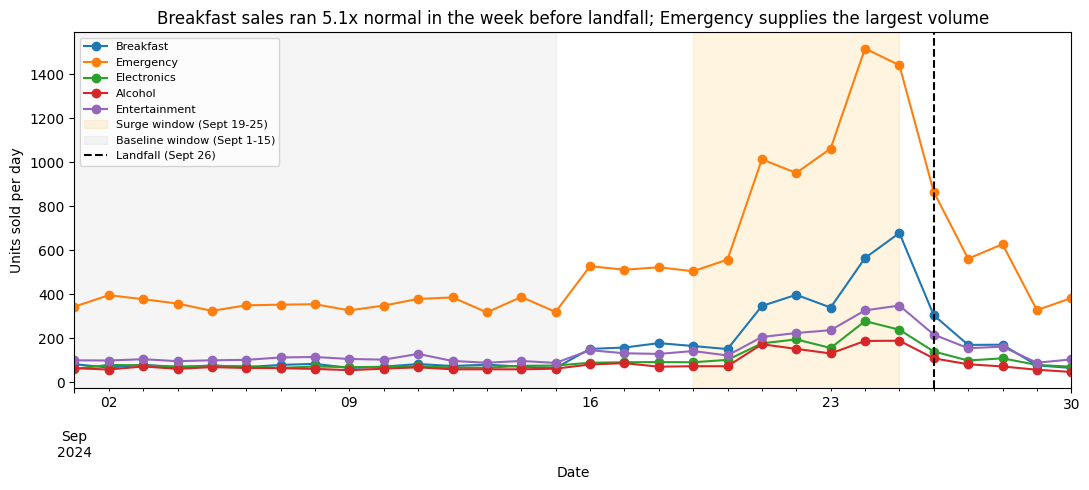

In [16]:
!git clone https://github.com/hpanjshiri/walmart-hurricane-project.git

%cd walmart-hurricane-project

%run notebooks/scratch/Data_Cleaning_Complete.ipynb

In [17]:
# TODO: the numbers

LANDFALL = pd.Timestamp('2024-09-26')
BASE = (pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15'))     # flat before first rise
SURGE = (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))    # 7 days before

# demand = units sold. Returns and sales with no timestamp are out
demand = clean[(~clean['is_return']) & clean['date'].notna()]
print('left out of Q1: returns =', int(clean['is_return'].sum()), '| sales with no timestamp =', int(clean['date'].isna().sum()))

def avg_per_day(frame, window, how='units'):
  start, end = window
  days = (end - start).days + 1
  w = frame[frame['date'].between(start, end)]
  total = w.groupby('category')['quantity'].sum() if how == 'units' else w.groupby('category').size()
  return total / days

def surge_table(base, surge, how='units'):
  t = pd.DataFrame({'baseline_per_day': avg_per_day(demand, base, how),
                      'surge_per_day': avg_per_day(demand, surge, how)})
  t['multiple'] = t['surge_per_day'] / t['baseline_per_day']
  t['pct_increase'] = (t['multiple'] - 1) * 100
  return t.sort_values('multiple', ascending=False)

t = surge_table(BASE, SURGE)
display(t.round(2))

def overall(base, surge, how='units'):
  f = lambda w: (demand[demand['date'].between(*w)]['quantity'].sum() if how == 'units'
                  else demand['date'].between(*w).sum()) / ((w[1] - w[0]).days + 1)
  return f(base), f(surge)

b_units, s_units = overall(BASE, SURGE)
b_orders, s_orders = overall(BASE, SURGE, how='orders')
top = t.index[0]
print(f"""
Baseline: {BASE[0].date()} to {BASE[1].date()} ({(BASE[1]-BASE[0]).days + 1} days)   Surge: {SURGE[0].date()} to {SURGE[1].date()} ({(SURGE[1]-SURGE[0]).days + 1} days, before the {LANDFALL.date()} landfall)
All categories, units:        {b_units:,.0f} -> {s_units:,.0f} per day = {s_units / b_units:.2f}x
All categories, order lines:  {b_orders:,.0f} -> {s_orders:,.0f} per day = {s_orders / b_orders:.2f}x
Biggest surge: {top}, {t.loc[top, 'baseline_per_day']:.1f} -> {t.loc[top, 'surge_per_day']:.1f} units/day = {t.loc[top, 'multiple']:.2f}x ({t.loc[top, 'pct_increase']:+.0f}%)
""")

# How much does the window choice matter?
choices = {
  'ours: baseline Sept 1-15, surge Sept 19-25':              ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))),
  'baseline runs through the climb (Sept 1-18)':             ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-18')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-25'))),
  'surge includes landfall day (Sept 19-26)':                ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-19'), pd.Timestamp('2024-09-26'))),
  'peak only: surge Sept 23-25 (3 days)':                    ((pd.Timestamp('2024-09-01'), pd.Timestamp('2024-09-15')), (pd.Timestamp('2024-09-23'), pd.Timestamp('2024-09-25'))),
}
rows = []
for name, (b, s) in choices.items():
  bu, su = overall(b, s)
  tt = surge_table(b, s)
  rows.append({'windows': name, 'all categories': round(su / bu, 2),
                'top category': tt.index[0], 'top multiple': round(tt['multiple'].iloc[0], 2)})
sens = pd.DataFrame(rows)
sens

left out of Q1: returns = 130 | sales with no timestamp = 884


,baseline_per_day,surge_per_day,multiple,pct_increase
category,,,,
Breakfast,73.27,376.86,5.14,414.36
Emergency,354.07,1006.43,2.84,184.25
Electronics,70.27,175.86,2.50,150.27
Alcohol,61.53,138.86,2.26,125.66
Entertainment,101.60,228.57,2.25,124.97
Health,42.33,95.00,2.24,124.41
Household,85.13,176.29,2.07,107.07
Grocery,171.07,306.57,1.79,79.21
Baby,85.20,133.71,1.57,56.94



Baseline: 2024-09-01 to 2024-09-15 (15 days)   Surge: 2024-09-19 to 2024-09-25 (7 days, before the 2024-09-26 landfall)
All categories, units:        1,103 -> 2,712 per day = 2.46x
All categories, order lines:  576 -> 1,361 per day = 2.36x
Biggest surge: Breakfast, 73.3 -> 376.9 units/day = 5.14x (+414%)



,windows,all categories,top category,top multiple
0,"ours: baseline Sept 1-15, surge Sept 19-25",2.46,Breakfast,5.14
1,baseline runs through the climb (Sept 1-18),2.31,Breakfast,4.28
2,surge includes landfall day (Sept 19-26),2.40,Breakfast,5.02
3,peak only: surge Sept 23-25 (3 days),3.19,Breakfast,7.19


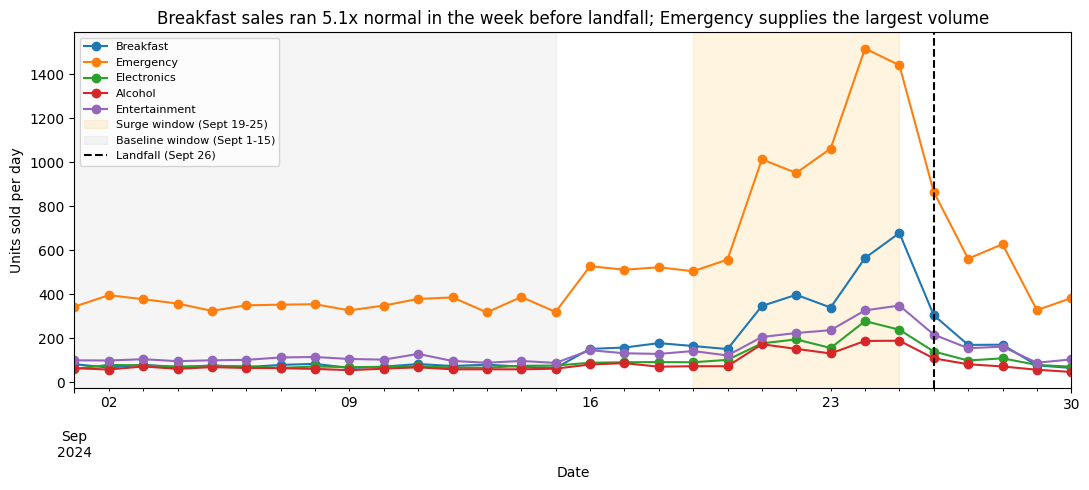

In [18]:
# TODO: the chart

top5 = t.head(5).index.tolist()
daily = (demand[demand['category'].isin(top5)]
        .groupby(['date', 'category'])['quantity'].sum().unstack('category').fillna(0))

fig, ax = plt.subplots(figsize=(11, 5))
daily[top5].plot(ax=ax, marker='o')
ax.axvspan(*SURGE, alpha=0.12, color='orange', label='Surge window (Sept 19-25)')
ax.axvspan(*BASE, alpha=0.08, color='gray', label='Baseline window (Sept 1-15)')
ax.axvline(LANDFALL, color='black', linestyle='--', label='Landfall (Sept 26)')
ax.set_title(f'{top} sales ran {t.loc[top, "multiple"]:.1f}x normal in the week before landfall; Emergency supplies the largest volume')
ax.set_xlabel('Date')
ax.set_ylabel('Units sold per day')
ax.legend(loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

**Q1 answer, in one sentence a manager could read:** Breakfast Foods saw the largest pre-hurricane demand surge, rising 414% to 5.14x its baseline daily sales in the seven days before Hurricane Helene's landfall.

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

Original distinct SKUs: 45
Canonical products after consolidation: 20
Largest consolidated family: POPTART-STRAWBERRY
Original SKUs in largest family: 4

BEFORE CONSOLIDATION


,sku,total_units
1,PT-12,1377
0,POPTART-STRAW,1294
2,PT_STRAWBERRY,1254
3,SKU#459812,1253



AFTER CONSOLIDATION


,canonical_sku,canonical_product_name,total_units
0,POPTART-STRAWBERRY,Strawberry Pop-Tarts,5178



Units before consolidation: 49,343
Units after consolidation:  49,343
Check passed: SKU consolidation did not change unit totals.



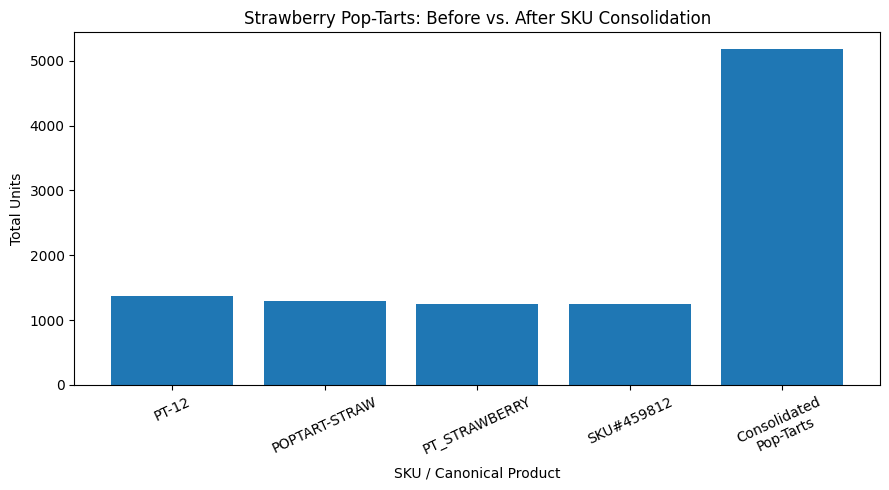

In [19]:
original_skus = clean['sku'].nunique()
canonical_products = clean['canonical_sku'].nunique()

# Number of original SKUs represented by each canonical product
sku_families = (
    clean.groupby('canonical_sku')['sku']
    .nunique()
    .sort_values(ascending=False)
)

largest_family = sku_families.index[0]
largest_family_size = sku_families.iloc[0]

print(f"Original distinct SKUs: {original_skus}")
print(f"Canonical products after consolidation: {canonical_products}")
print(f"Largest consolidated family: {largest_family}")
print(f"Original SKUs in largest family: {largest_family_size}")

# Before consolidation, 4 separate
poptart_before = (
    clean[clean['canonical_sku'] == 'POPTART-STRAWBERRY']
    .groupby('sku', as_index=False)
    .agg(total_units=('quantity', 'sum'))
    .sort_values('total_units', ascending=False)
)

print("\nBEFORE CONSOLIDATION")
display(poptart_before)

# After consolidation, appear as one
poptart_after = (
    clean[clean['canonical_sku'] == 'POPTART-STRAWBERRY']
    .groupby(['canonical_sku', 'canonical_product_name'], as_index=False)
    .agg(total_units=('quantity', 'sum'))
)

print("\nAFTER CONSOLIDATION")
display(poptart_after)

# Verify that SKU consolidation only changes product grouping
units_before = clean['quantity'].sum()

units_after = (
    clean.groupby('canonical_sku')['quantity']
    .sum()
    .sum()
)

assert units_before == units_after, \
    "SKU consolidation changed total unit quantity!"

print(f"\nUnits before consolidation: {units_before:,}")
print(f"Units after consolidation:  {units_after:,}")
print("Check passed: SKU consolidation did not change unit totals.\n")

fig, ax = plt.subplots(figsize=(9, 5))

labels = list(poptart_before['sku']) + ['Consolidated\nPop-Tarts']
values = list(poptart_before['total_units']) + [poptart_after['total_units'].iloc[0]]

ax.bar(labels, values)

ax.set_title('Strawberry Pop-Tarts: Before vs. After SKU Consolidation')
ax.set_ylabel('Total Units')
ax.set_xlabel('SKU / Canonical Product')
ax.tick_params(axis='x', rotation=25)

plt.tight_layout()
plt.show()

**Q2 answer:** SKU consolidation reduced 45 fragmented SKUs to 20 canonical products; the largest family was Strawberry Pop-Tarts, where four separate SKUs totaling 5,178 units were combined into one product without changing overall unit sales.

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

Tallahassee store rows found: 1
Stores with coordinates: 12

Weather source: Open-Meteo historical API
Stores with failed API calls: []
Weather records returned: 372
Stores with weather: 12

Rows before join: 25532
Rows after join: 25532
Rows lost: 0
Transactions with rainfall: 24648
Transactions missing rainfall: 884

WEATHER-SALES CORRELATIONS


,Weather variable,Pearson r,Days analyzed
0,Rainfall (same day),-0.298,30
1,Wind speed (same day),0.240,30
2,Pressure (same day),-0.282,30
3,Rainfall (1-day lag),-0.550,30
4,Wind speed (1-day lag),0.045,30
5,Pressure (1-day lag),-0.204,30



Daily dataset preview:


,units_sold,avg_rainfall_mm,avg_wind_kmh,avg_pressure_hpa,rain_lag1_mm,wind_lag1_kmh,pressure_lag1_hpa
date,,,,,,,
2024-09-01,1060,8.266667,16.141667,1013.925000,3.708333,17.083333,1015.775000
2024-09-02,1168,7.508333,14.008333,1013.733333,8.266667,16.141667,1013.925000
2024-09-03,1162,13.566667,17.358333,1015.433333,7.508333,14.008333,1013.733333
2024-09-04,1115,14.516667,17.541667,1017.616667,13.566667,17.358333,1015.433333
2024-09-05,1076,11.425000,16.625000,1016.958333,14.516667,17.541667,1017.616667


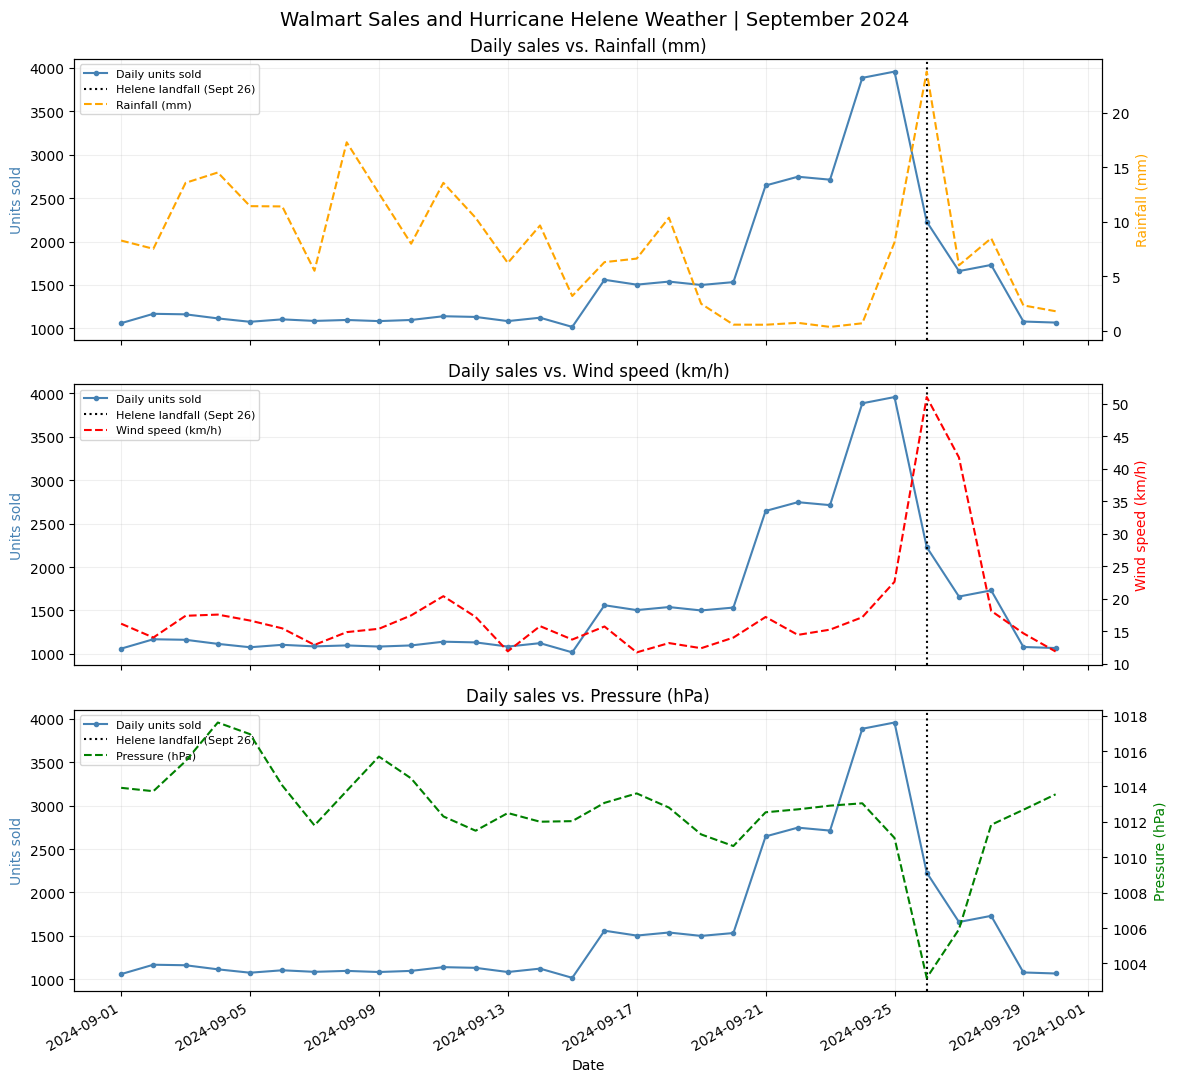


========== Q3 CHECKPOINT ==========
Data source: Open-Meteo historical API
Period: 2024-09-01 to 2024-09-30
Coordinate proxy: FL-619 Tallahassee city center
Store locations: 12
Stores with weather: 12
Join: 25,532 -> 25,532 rows
Rows lost: 0
Days analyzed: 30

Correlations:
Rainfall (same day): -0.298 (n=30)
Wind speed (same day): 0.240 (n=30)
Pressure (same day): -0.282 (n=30)
Rainfall (1-day lag): -0.550 (n=30)
Wind speed (1-day lag): 0.045 (n=30)
Pressure (1-day lag): -0.204 (n=30)

Missing-weather transactions: 884
Failed API stores: []
Lag: prior-day weather vs current-day sales
Correlation does not establish causation.


In [15]:


import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import time


START = "2024-09-01"
END = "2024-09-30"

FETCH_START = (
    pd.Timestamp(START) - pd.Timedelta(days=1)
).strftime("%Y-%m-%d")

sales = clean.copy()
sales["date"] = pd.to_datetime(
    sales["date"], errors="coerce"
).dt.normalize()

rows_before = len(sales)

stores_fixed = stores_clean.copy()

stores_fixed["latitude"] = pd.to_numeric(
    stores_fixed["latitude"], errors="coerce"
)
stores_fixed["longitude"] = pd.to_numeric(
    stores_fixed["longitude"], errors="coerce"
)

tallahassee = (
    stores_fixed["store_id"].astype(str).str.strip()
    == "FL-619"
)

stores_fixed.loc[
    tallahassee & stores_fixed["latitude"].isna(),
    "latitude"
] = 30.4383

stores_fixed.loc[
    tallahassee & stores_fixed["longitude"].isna(),
    "longitude"
] = -84.2807

print("Tallahassee store rows found:", tallahassee.sum())
assert tallahassee.any(), "FL-619 not found in stores_clean"

store_coords = (
    stores_fixed[
        ["store_id", "latitude", "longitude"]
    ]
    .dropna()
    .drop_duplicates("store_id")
)

print("Stores with coordinates:", len(store_coords))

weather_rows = []
failed_stores = []

url = "https://archive-api.open-meteo.com/v1/archive"

for _, store in store_coords.iterrows():

    params = {
        "latitude": float(store["latitude"]),
        "longitude": float(store["longitude"]),
        "start_date": FETCH_START,
        "end_date": END,
        "daily": (
            "precipitation_sum,"
            "wind_speed_10m_max,"
            "pressure_msl_mean"
        ),
        "timezone": "America/New_York",
        "wind_speed_unit": "kmh"
    }

    for attempt in range(3):
        try:
            response = requests.get(
                url, params=params, timeout=30
            )
            response.raise_for_status()
            data = response.json()["daily"]

            for i, date in enumerate(data["time"]):
                weather_rows.append({
                    "store_id": store["store_id"],
                    "date": pd.Timestamp(date),
                    "rainfall_mm":
                        data["precipitation_sum"][i],
                    "wind_speed_kmh":
                        data["wind_speed_10m_max"][i],
                    "pressure_hpa":
                        data["pressure_msl_mean"][i],
                    "source": "Open-Meteo historical API"
                })

            break

        except (
            requests.RequestException,
            KeyError,
            ValueError,
            TypeError
        ) as e:
            if attempt == 2:
                failed_stores.append(store["store_id"])
                print(
                    "Weather unavailable:",
                    store["store_id"], e
                )
            else:
                time.sleep(2 ** attempt)

weather = pd.DataFrame(
    weather_rows,
    columns=[
        "store_id", "date", "rainfall_mm",
        "wind_speed_kmh", "pressure_hpa", "source"
    ]
)

for col in [
    "rainfall_mm", "wind_speed_kmh", "pressure_hpa"
]:
    weather[col] = pd.to_numeric(
        weather[col], errors="coerce"
    )

weather = weather.sort_values(
    ["store_id", "date"]
).reset_index(drop=True)

assert not weather.duplicated(
    ["store_id", "date"]
).any()

print("\nWeather source: Open-Meteo historical API")
print("Stores with failed API calls:", failed_stores)
print("Weather records returned:", len(weather))
print(
    "Stores with weather:",
    weather["store_id"].nunique()
)


weather["rainfall_lag1_mm"] = (
    weather.groupby("store_id")["rainfall_mm"].shift(1)
)

weather["wind_lag1_kmh"] = (
    weather.groupby("store_id")["wind_speed_kmh"].shift(1)
)

weather["pressure_lag1_hpa"] = (
    weather.groupby("store_id")["pressure_hpa"].shift(1)
)

weather = weather[
    weather["date"].between(START, END)
].copy()

joined = sales.merge(
    weather,
    on=["store_id", "date"],
    how="left",
    validate="many_to_one"
)

rows_after = len(joined)

assert rows_before == rows_after, (
    "Join changed transaction count!"
)

print("\nRows before join:", rows_before)
print("Rows after join:", rows_after)
print("Rows lost:", rows_before - rows_after)

print(
    "Transactions with rainfall:",
    joined["rainfall_mm"].notna().sum()
)
print(
    "Transactions missing rainfall:",
    joined["rainfall_mm"].isna().sum()
)
valid = joined[
    (joined["quantity"] > 0) &
    (joined["date"].notna()) &
    (joined["rainfall_mm"].notna())
].copy()

daily_sales = (
    valid.groupby("date")["quantity"]
    .sum()
    .rename("units_sold")
)

daily_weather = (
    weather.groupby("date")
    .agg(
        avg_rainfall_mm=("rainfall_mm", "mean"),
        avg_wind_kmh=("wind_speed_kmh", "mean"),
        avg_pressure_hpa=("pressure_hpa", "mean"),
        rain_lag1_mm=("rainfall_lag1_mm", "mean"),
        wind_lag1_kmh=("wind_lag1_kmh", "mean"),
        pressure_lag1_hpa=("pressure_lag1_hpa", "mean")
    )
)

daily = pd.concat(
    [daily_sales, daily_weather], axis=1
).sort_index()

weather_variables = [
    "avg_rainfall_mm",
    "avg_wind_kmh",
    "avg_pressure_hpa",
    "rain_lag1_mm",
    "wind_lag1_kmh",
    "pressure_lag1_hpa"
]

labels = {
    "avg_rainfall_mm": "Rainfall (same day)",
    "avg_wind_kmh": "Wind speed (same day)",
    "avg_pressure_hpa": "Pressure (same day)",
    "rain_lag1_mm": "Rainfall (1-day lag)",
    "wind_lag1_kmh": "Wind speed (1-day lag)",
    "pressure_lag1_hpa": "Pressure (1-day lag)"
}

results = []

for col in weather_variables:
    subset = daily[["units_sold", col]].dropna()

    if (
        len(subset) >= 3
        and subset["units_sold"].nunique() > 1
        and subset[col].nunique() > 1
    ):
        r = subset["units_sold"].corr(subset[col])
    else:
        r = np.nan

    results.append({
        "Weather variable": labels[col],
        "Pearson r": r,
        "Days analyzed": len(subset)
    })

correlation_table = pd.DataFrame(results)

print("\nWEATHER-SALES CORRELATIONS")
display(correlation_table.round(3))
print("\nDaily dataset preview:")
display(daily.head())

correlation = correlation_table.loc[
    correlation_table["Weather variable"]
    == "Rainfall (same day)",
    "Pearson r"
].iloc[0]

n_days = daily[
    ["units_sold", "avg_rainfall_mm"]
].dropna().shape[0]

fig, axes = plt.subplots(
    3, 1, figsize=(12, 11), sharex=True
)

plot_vars = [
    ("avg_rainfall_mm", "Rainfall (mm)", "orange"),
    ("avg_wind_kmh", "Wind speed (km/h)", "red"),
    ("avg_pressure_hpa", "Pressure (hPa)", "green")
]

for ax, (column, ylabel, color) in zip(
    axes, plot_vars
):
    ax.plot(
        daily.index,
        daily["units_sold"],
        color="steelblue",
        marker="o",
        markersize=3,
        label="Daily units sold"
    )
    ax.set_ylabel("Units sold", color="steelblue")

    ax2 = ax.twinx()
    ax2.plot(
        daily.index,
        daily[column],
        color=color,
        linestyle="--",
        label=ylabel
    )
    ax2.set_ylabel(ylabel, color=color)

    ax.axvline(
        pd.Timestamp("2024-09-26"),
        color="black",
        linestyle=":",
        label="Helene landfall (Sept 26)"
    )

    ax.set_title(f"Daily sales vs. {ylabel}")
    ax.grid(alpha=0.2)

    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper left",
        fontsize=8
    )

axes[-1].set_xlabel("Date")
fig.suptitle(
    "Walmart Sales and Hurricane Helene Weather | September 2024",
    fontsize=14
)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

print("\n========== Q3 CHECKPOINT ==========")
print("Data source: Open-Meteo historical API")
print("Period:", START, "to", END)
print("Coordinate proxy: FL-619 Tallahassee city center")
print("Store locations:", len(store_coords))
print("Stores with weather:", weather["store_id"].nunique())
print(f"Join: {rows_before:,} -> {rows_after:,} rows")
print("Rows lost:", rows_before - rows_after)
print("Days analyzed:", n_days)

print("\nCorrelations:")
for _, row in correlation_table.iterrows():
    print(
        f"{row['Weather variable']}: "
        f"{row['Pearson r']:.3f} "
        f"(n={int(row['Days analyzed'])})"
    )

print("\nMissing-weather transactions:",
      joined["rainfall_mm"].isna().sum())
print("Failed API stores:", failed_stores)
print("Lag: prior-day weather vs current-day sales")
print("Correlation does not establish causation.")
print("===================================")


**Q3 answer, with its caveat:** We used historical daily precipitation data from the Open-Meteo API for September 1–30, 2024, and matched it with our cleaned Walmart transactions using store ID and date. We validated the merge to ensure that no transaction rows were lost.

We then calculated the Pearson correlation between average daily rainfall and total daily units sold to examine whether wetter conditions were associated with changes in demand during the hurricane period.

**Caveat:** The analysis covers only one month, with at most 30 daily observations. Stores with missing coordinates or unavailable weather data are excluded from the correlation. Additionally, correlation does not imply causation: hurricane warnings, stockpiling behavior, and store operations may also influence sales.

### Q4 and Q5 — where they stand

**TODO:** one honest sentence each on the remaining two questions and who is finishing them this weekend.

**Q4 (stores and geography):** IN Progress, extra time given. (Dina)

**Q5 (signal or artifact):** IN Progress, extra time given. (Maya)

### Self-check

In [20]:
progress = {
    'q1_multiple': 5.14,            # TODO: a number
    'q1_baseline_window': '2024-09-01 to 2024-09-15',   # TODO: stated explicitly
    'q2_canonical_products': 20,  # TODO: a number
    'q3_join_rows_preserved': True, # TODO: True/False
    'q3_days_in_correlation': 30, # TODO: a number
    'charts_with_message_titles': 2,  # TODO: how many
    'notebook_runs_clean': True,   # TODO: True after Restart and Run All
    'repo_pushed': True,           # TODO
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.14
PASS - q1_baseline_window = 2024-09-01 to 2024-09-15
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 30
PASS - charts_with_message_titles = 2
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

One finding that surprised us was that the category column had 37 different spellings for what should have been only 10 categories. Two variants, “Games & Entertainment” and “Health & Wellness,” even slipped past our first mapping and initially appeared as separate categories, splitting observations that should have been grouped under Entertainment and Health. We caught this by checking the unique category values after cleaning, corrected the mapping, and then validated that exactly 10 categories remained and that our row counts still reconciled: 25,562 raw rows, 30 duplicates removed, and 25,532 clean rows.

The number we are least confident in is the exact magnitude of Breakfast's 5.14x demand surge. That result depends on how the baseline period is defined: using Sept. 1-15 gives a 5.14x surge, while extending the baseline through Sept. 18 lowers it to 4.28x because sales had already begun increasing by Sept. 16. In addition, 884 transactions (3.5% of the cleaned rows) have no timestamp and therefore cannot be assigned to either period. We are confident that Breakfast experienced a substantial surge, but less confident that 5.14x represents its exact magnitude.